# Initial Profiling. Spotify and Grammy CSVs

## 0. Load the raw CSV files

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Works when Jupyter starts in the repository root or in the notebooks/ folder.
raw_dirs = [Path.cwd() / "data" / "raw", Path.cwd().parent / "data" / "raw"]
RAW_DIR = next((p for p in raw_dirs if
                (p / "spotify_dataset.csv").is_file() and
                (p / "the_grammy_awards.csv").is_file()), None)
if RAW_DIR is None:
    raise FileNotFoundError("Both CSVs must be available in data/raw/. Start Jupyter from the repository root or notebooks/.")

spotify = pd.read_csv(RAW_DIR / "spotify_dataset.csv")
grammy = pd.read_csv(RAW_DIR / "the_grammy_awards.csv")

print("Spotify CSV:", RAW_DIR / "spotify_dataset.csv", "| shape:", spotify.shape)
print("Grammy CSV: ", RAW_DIR / "the_grammy_awards.csv", "| shape:", grammy.shape)
print("\nSpotify sample:")
display(spotify.head(5))
print("Grammy sample:")
display(grammy.head(5))

Spotify CSV: /mnt/data/profile_test_project/data/raw/spotify_dataset.csv | shape: (114000, 21)
Grammy CSV:  /mnt/data/profile_test_project/data/raw/the_grammy_awards.csv | shape: (4810, 10)

Spotify sample:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Soundtrack),Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Grammy sample:


,year,title,published_at,updated_at,category,nominee,artist,workers,img,winner
0,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Bad Guy,Billie Eilish,"Finneas O'Connell, producer; Rob Kinelski & Finneas O'Connell, engineers/mix...",https://www.grammy.com/sites/com/files/styles/artist_circle/public/muzooka/B...,True
1,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,"Hey, Ma",Bon Iver,"BJ Burton, Brad Cook, Chris Messina & Justin Vernon, producers; BJ Burton, Z...",https://www.grammy.com/sites/com/files/styles/artist_circle/public/muzooka/B...,True
2,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,7 rings,Ariana Grande,"Charles Anderson, Tommy Brown, Michael Foster & Victoria Monet, producers; S...",https://www.grammy.com/sites/com/files/styles/artist_circle/public/muzooka/A...,True
3,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Hard Place,H.E.R.,"Rodney “Darkchild” Jerkins, producer; Joseph Hurtado, Jaycen Joshua, Derek K...",https://www.grammy.com/sites/com/files/styles/artist_circle/public/muzooka/H...,True
4,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Talk,Khalid,"Disclosure & Denis Kosiak, producers; Ingmar Carlson, Jon Castelli, Josh Deg...",https://www.grammy.com/sites/com/files/styles/artist_circle/public/muzooka/K...,True


# Spotify profiling

## 1. General structure and completeness

In [2]:
print("Spotify structure")
spotify.info()
spotify_profile = pd.DataFrame({
    "type": spotify.dtypes.astype(str),
    "non_null": spotify.notna().sum(),
    "missing": spotify.isna().sum(),
    "distinct": spotify.nunique(dropna=True),
})
display(spotify_profile)

print("Columns with missing values:")
display(spotify_profile.loc[spotify_profile["missing"] > 0, ["missing", "type", "distinct"]])
print("Rows with at least one missing value:", int(spotify.isna().any(axis=1).sum()))

Spotify structure
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  li

,type,non_null,missing,distinct
Unnamed: 0,int64,114000,0,114000
track_id,object,114000,0,89741
artists,object,113999,1,31437
album_name,object,113999,1,46589
track_name,object,113999,1,73608
popularity,int64,114000,0,101
duration_ms,int64,114000,0,50697
explicit,bool,114000,0,2
danceability,float64,114000,0,1174
energy,float64,114000,0,2083


Columns with missing values:


,missing,type,distinct
artists,1,object,31437
album_name,1,object,46589
track_name,1,object,73608


Rows with at least one missing value: 1


## 2. Repeated records and row grain

In [3]:
# Compare complete rows first, then inspect any exported index-like column.
print("Duplicate rows considering every CSV column:", int(spotify.duplicated().sum()))
index_cols = [c for c in spotify.columns if str(c).strip().lower().startswith("unnamed:")]
print("Index-like columns:", index_cols if index_cols else "None found")
spotify_data_cols = [c for c in spotify.columns if c not in index_cols]
print("Duplicate rows excluding index-like columns:", int(spotify.duplicated(subset=spotify_data_cols).sum()))

if {"track_id", "track_genre"}.issubset(spotify.columns):
    genres_per_track = spotify.groupby("track_id")["track_genre"].nunique()
    print("Total rows:", len(spotify))
    print("Distinct track_id:", spotify["track_id"].nunique())
    print("Distinct (track_id, track_genre) pairs:", spotify.drop_duplicates(["track_id", "track_genre"]).shape[0])
    print("Tracks listed under multiple genres:", int((genres_per_track > 1).sum()))
    print("Maximum genres for one track:", int(genres_per_track.max()))

# Multiple rows per track can be legitimate; check whether selected track-level values vary.
value_cols = [c for c in ["popularity", "duration_ms", "danceability", "energy", "loudness", "tempo"] if c in spotify.columns]
repeat_rows = spotify[spotify.duplicated("track_id", keep=False)] if "track_id" in spotify.columns else pd.DataFrame()
if not repeat_rows.empty and value_cols:
    differences = repeat_rows.groupby("track_id")[value_cols].nunique().gt(1).any(axis=1)
    print("Repeated track IDs with different selected values:", int(differences.sum()))

Duplicate rows considering every CSV column: 0
Index-like columns: ['Unnamed: 0']


Duplicate rows excluding index-like columns: 450


Total rows: 114000
Distinct track_id: 89741
Distinct (track_id, track_genre) pairs: 113550


Tracks listed under multiple genres: 16299
Maximum genres for one track: 9
Repeated track IDs with different selected values: 720


## 3. Genres, artists and titles

Distinct non-null genres: 114
Rows per genre — minimum / median / maximum: 1000 1000.0 1000
Most frequent genres:


,rows
track_genre,
acoustic,1000
afrobeat,1000
alt-rock,1000
alternative,1000
ambient,1000
anime,1000
black-metal,1000
bluegrass,1000
blues,1000


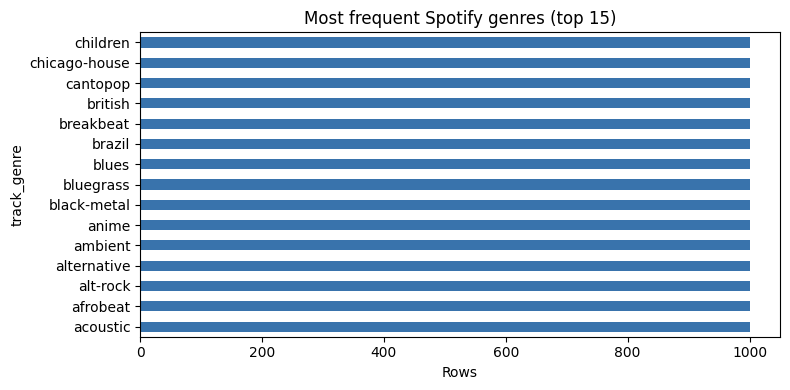

Rows with multiple artist names separated by ';': 30075
Maximum artist names in one row: 38
Missing artist values: 1
Titles used by more than one track_id: 7991


,distinct_track_ids
track_name,
Rockin' Around The Christmas Tree,48
Frosty The Snowman,45
Little Saint Nick - 1991 Remix,41
Run Rudolph Run,40
Santa Claus Is Coming To Town,38


In [4]:
if "track_genre" in spotify.columns:
    genre_counts = spotify["track_genre"].value_counts(dropna=False)
    print("Distinct non-null genres:", spotify["track_genre"].nunique())
    print("Rows per genre — minimum / median / maximum:", int(genre_counts.min()), float(genre_counts.median()), int(genre_counts.max()))
    print("Most frequent genres:")
    display(genre_counts.head(10).to_frame("rows"))
    genre_counts.head(15).sort_values().plot(kind="barh", figsize=(8, 4), color="#3973AC", title="Most frequent Spotify genres (top 15)")
    plt.xlabel("Rows")
    plt.tight_layout()
    plt.show()

if "artists" in spotify.columns:
    artist_values = spotify["artists"].dropna().astype(str)
    artists_per_row = artist_values.str.split(";").map(len)
    print("Rows with multiple artist names separated by ';':", int((artists_per_row > 1).sum()))
    print("Maximum artist names in one row:", int(artists_per_row.max()))
    print("Missing artist values:", int(spotify["artists"].isna().sum()))

if {"track_name", "track_id"}.issubset(spotify.columns):
    ids_per_title = spotify.groupby("track_name")["track_id"].nunique()
    repeated_titles = ids_per_title[ids_per_title > 1].sort_values(ascending=False)
    print("Titles used by more than one track_id:", len(repeated_titles))
    display(repeated_titles.head(5).to_frame("distinct_track_ids"))

## 4. Numeric fields, ranges and possible sentinel values

Numeric columns: ['Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500,32909.110,0.000,28499.750,56999.500,85499.250,113999.000
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
key,114000.0,5.309,3.560,0.000,2.000,5.000,8.000,11.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
mode,114000.0,0.638,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996


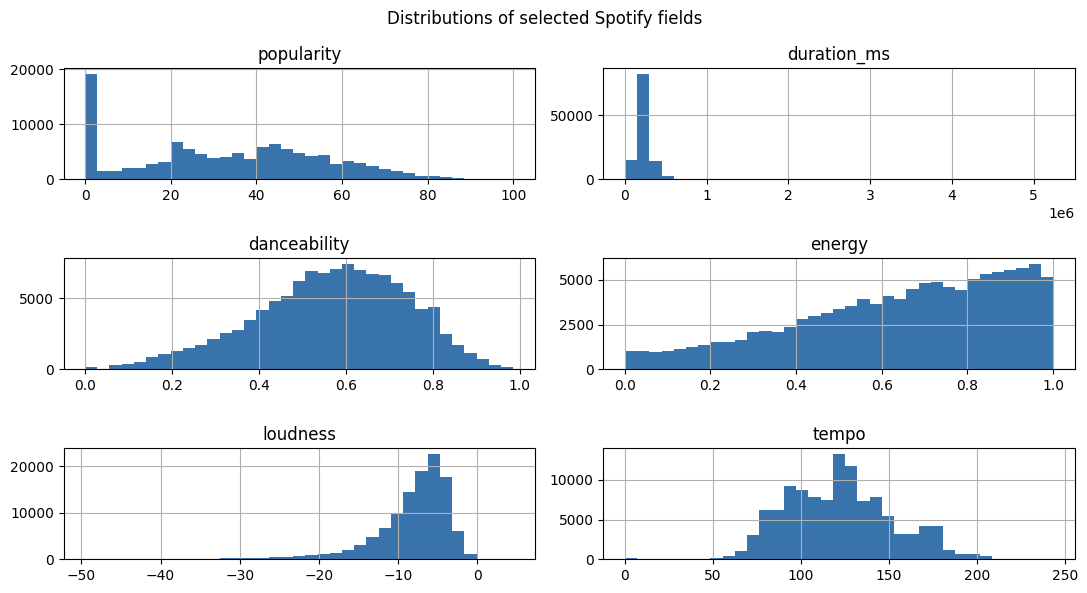

Popularity percentiles:


,popularity
count,114000.000000
mean,33.238535
std,22.305078
min,0.000000
25%,17.000000
50%,35.000000
75%,50.000000
90%,63.000000
99%,80.000000
max,100.000000


Rows with popularity = 0: 16020
Duration minutes — median: 3.55 | maximum: 87.29
Rows longer than 10 minutes: 603 | zero-duration rows: 1
tempo = 0: 157
time_signature = 0: 163
danceability = 0: 157
speechiness = 0: 157
valence = 0: 176
Rows where selected audio fields are all zero: 157
Columns that look date/year-related: None found


In [5]:
numeric_cols = spotify.select_dtypes(include="number").columns.tolist()
print("Numeric columns:", numeric_cols)
display(spotify[numeric_cols].describe().T.round(3))

plot_cols = [c for c in ["popularity", "duration_ms", "danceability", "energy", "loudness", "tempo"] if c in spotify.columns]
if plot_cols:
    spotify[plot_cols].hist(bins=35, figsize=(11, 6), color="#3973AC")
    plt.suptitle("Distributions of selected Spotify fields")
    plt.tight_layout()
    plt.show()

if "popularity" in spotify.columns:
    print("Popularity percentiles:")
    display(spotify["popularity"].describe(percentiles=[.25, .50, .75, .90, .99]).to_frame("popularity"))
    print("Rows with popularity = 0:", int((spotify["popularity"] == 0).sum()))
if "duration_ms" in spotify.columns:
    duration_min = spotify["duration_ms"] / 60000
    print("Duration minutes — median:", round(float(duration_min.median()), 2), "| maximum:", round(float(duration_min.max()), 2))
    print("Rows longer than 10 minutes:", int((duration_min > 10).sum()), "| zero-duration rows:", int((spotify["duration_ms"] == 0).sum()))

for col in ["tempo", "time_signature", "danceability", "speechiness", "valence"]:
    if col in spotify.columns:
        print(f"{col} = 0:", int((spotify[col] == 0).sum()))
zero_audio = [c for c in ["danceability", "speechiness", "valence"] if c in spotify.columns]
if zero_audio:
    print("Rows where selected audio fields are all zero:", int((spotify[zero_audio] == 0).all(axis=1).sum()))

date_cols = [c for c in spotify.columns if re.search(r"date|year|release|month|created|updated|timestamp", str(c), re.I)]
print("Columns that look date/year-related:", date_cols if date_cols else "None found")

# Grammy Awards profiling

## 5. General structure and completeness

In [6]:
print("Grammy structure")
grammy.info()
grammy_profile = pd.DataFrame({
    "type": grammy.dtypes.astype(str),
    "non_null": grammy.notna().sum(),
    "missing": grammy.isna().sum(),
    "distinct": grammy.nunique(dropna=True),
})
display(grammy_profile)
print("Columns with missing values:")
display(grammy_profile.loc[grammy_profile["missing"] > 0, ["missing", "type", "distinct"]])
print("Rows with at least one missing value:", int(grammy.isna().any(axis=1).sum()))

Grammy structure
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          4810 non-null   int64 
 1   title         4810 non-null   object
 2   published_at  4810 non-null   object
 3   updated_at    4810 non-null   object
 4   category      4810 non-null   object
 5   nominee       4804 non-null   object
 6   artist        2970 non-null   object
 7   workers       2620 non-null   object
 8   img           3443 non-null   object
 9   winner        4810 non-null   bool  
dtypes: bool(1), int64(1), object(8)
memory usage: 343.0+ KB


,type,non_null,missing,distinct
year,int64,4810,0,62
title,object,4810,0,62
published_at,object,4810,0,4
updated_at,object,4810,0,10
category,object,4810,0,638
nominee,object,4804,6,4131
artist,object,2970,1840,1658
workers,object,2620,2190,2366
img,object,3443,1367,1463
winner,bool,4810,0,1


Columns with missing values:


,missing,type,distinct
nominee,6,object,4131
artist,1840,object,1658
workers,2190,object,2366
img,1367,object,1463


Rows with at least one missing value: 3976


## 6. Duplicate rows and candidate key

In [7]:
print("Exact duplicate rows across all columns:", int(grammy.duplicated().sum()))
key_cols = [c for c in ["year", "category", "nominee"] if c in grammy.columns]
if len(key_cols) == 3:
    repeated_key_rows = grammy.duplicated(key_cols, keep=False)
    print("Rows belonging to repeated (year, category, nominee) keys:", int(repeated_key_rows.sum()))
    display(grammy.loc[repeated_key_rows, key_cols].sort_values(key_cols).head(10))
else:
    print("Candidate key (year, category, nominee) cannot be checked because a column is missing.")

Exact duplicate rows across all columns: 0
Rows belonging to repeated (year, category, nominee) keys: 0


,year,category,nominee


## 7. Years and repeated year/category groups

Observed year range: 1958 to 2019
Distinct years: 62
Rows per year — summary:


,rows
count,62.000000
mean,77.580645
std,51.744818
min,28.000000
25%,48.000000
50%,75.500000
75%,88.750000
max,433.000000


Years with the most rows:


,rows
year,
2019,433
2007,111
2008,111
2006,110
2010,109
2009,109
2005,108
2004,107
2003,105


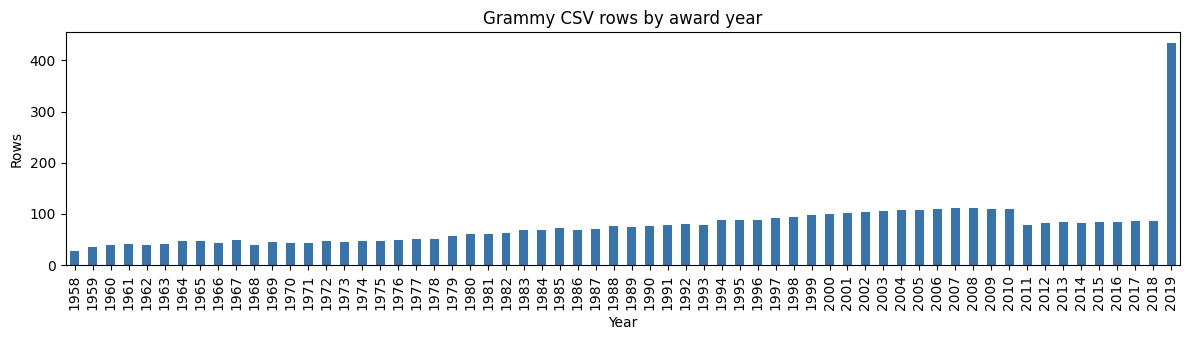

Year/category groups with more than one row: 115
Number of repeated year/category groups by year:


,repeated_groups
year,
1959,1
1961,1
1966,1
1967,2
1974,1
1977,1
1982,1
1983,1
1984,2


Examples with the most rows:


,year,category,rows
31,2019,Album Of The Year,8
113,2019,Record Of The Year,8
80,2019,Best New Artist,8
114,2019,Song Of The Year,8
52,2019,Best Contemporary Classical Composition,6
37,2019,"Best Arrangement, Instrumental or A Cappella",5
38,2019,"Best Arrangement, Instruments and Vocals",5
35,2019,Best American Roots Song,5
36,2019,Best Americana Album,5
41,2019,Best Chamber Music/Small Ensemble Performance,5


In [8]:
if "year" in grammy.columns:
    rows_by_year = grammy["year"].value_counts().sort_index()
    print("Observed year range:", rows_by_year.index.min(), "to", rows_by_year.index.max())
    print("Distinct years:", len(rows_by_year))
    print("Rows per year — summary:")
    display(rows_by_year.describe().to_frame("rows"))
    print("Years with the most rows:")
    display(rows_by_year.sort_values(ascending=False).head(10).to_frame("rows"))
    rows_by_year.plot(kind="bar", figsize=(12, 3.5), color="#3973AC", title="Grammy CSV rows by award year")
    plt.xlabel("Year")
    plt.ylabel("Rows")
    plt.tight_layout()
    plt.show()

if {"year", "category"}.issubset(grammy.columns):
    year_category_rows = grammy.groupby(["year", "category"], dropna=False).size().rename("rows")
    repeated_year_category = year_category_rows[year_category_rows > 1].reset_index()
    print("Year/category groups with more than one row:", len(repeated_year_category))
    if not repeated_year_category.empty:
        print("Number of repeated year/category groups by year:")
        display(repeated_year_category.groupby("year").size().rename("repeated_groups").to_frame())
        print("Examples with the most rows:")
        display(repeated_year_category.sort_values("rows", ascending=False).head(10))
    else:
        print("No repeated year/category groups found.")

## 8. `winner`, categories and text fields

In [9]:
if "winner" in grammy.columns:
    print("Observed winner values:")
    display(grammy["winner"].value_counts(dropna=False).to_frame("rows"))
    print("Distinct winner values including missing:", grammy["winner"].nunique(dropna=False))

if "category" in grammy.columns:
    category_counts = grammy["category"].value_counts(dropna=False)
    print("Distinct non-null categories:", grammy["category"].nunique())
    print("Most frequent categories:")
    display(category_counts.head(10).to_frame("rows"))
    print("Category row-count summary:")
    display(category_counts.describe().to_frame("rows_per_category"))

for col in ["nominee", "artist", "workers", "img"]:
    if col in grammy.columns:
        print(f"{col}: missing={int(grammy[col].isna().sum()):,}; distinct non-null={grammy[col].nunique(dropna=True):,}")

if {"artist", "workers"}.issubset(grammy.columns):
    print("Rows with missing artist but non-missing workers:", int((grammy["artist"].isna() & grammy["workers"].notna()).sum()))

Observed winner values:


,rows
winner,
True,4810


Distinct winner values including missing: 1
Distinct non-null categories: 638
Most frequent categories:


,rows
category,
Song Of The Year,70
Record Of The Year,69
Album Of The Year,66
Best Opera Recording,64
Best Album Notes,63
Best Instrumental Composition,55
Best Country Song,55
Best New Artist,51
Best Historical Album,44


Category row-count summary:


,rows_per_category
count,638.000000
mean,7.539185
std,10.225443
min,1.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,70.000000


nominee: missing=6; distinct non-null=4,131
artist: missing=1,840; distinct non-null=1,658
workers: missing=2,190; distinct non-null=2,366
img: missing=1,367; distinct non-null=1,463
Rows with missing artist but non-missing workers: 1654


## 9. Publication and update timestamps

In [10]:
for col in ["published_at", "updated_at"]:
    if col in grammy.columns:
        parsed = pd.to_datetime(grammy[col], errors="coerce", utc=True)
        print(f"{col}: unparseable={int(parsed.isna().sum())}; earliest={parsed.min()}; latest={parsed.max()}")
        offset_count = grammy[col].astype(str).str.contains(r"[+-][0-9]{2}:[0-9]{2}$", regex=True).sum()
        print(f"{col}: source values ending with a timezone offset={int(offset_count)}")

if {"published_at", "year"}.issubset(grammy.columns):
    publication_year = pd.to_datetime(grammy["published_at"], errors="coerce", utc=True).dt.year
    comparable = publication_year.notna() & grammy["year"].notna()
    same_year = int((publication_year[comparable] == grammy.loc[comparable, "year"]).sum())
    print("Rows where published_at calendar year equals award year:", same_year, "of", int(comparable.sum()))

published_at: unparseable=0; earliest=2017-11-28 08:03:45+00:00; latest=2020-05-19 12:10:28+00:00
published_at: source values ending with a timezone offset=4810
updated_at: unparseable=0; earliest=2017-11-28 08:03:45+00:00; latest=2020-09-01 19:16:40+00:00
updated_at: source values ending with a timezone offset=4810
Rows where published_at calendar year equals award year: 86 of 4810


## 10. What the raw profile reveals for Workshop 2

This short table collects observations calculated above. It helps explain the later ETL decisions; it is not a validation suite and does not modify data.

In [11]:
observations = [
    ("Spotify", "Structure", f"{spotify.shape[0]:,} rows x {spotify.shape[1]} columns."),
    ("Spotify", "Missing values", f"{int(spotify.isna().sum().sum()):,} missing cells across {int((spotify.isna().sum() > 0).sum())} columns."),
    ("Spotify", "Repeated data rows", f"{int(spotify.duplicated().sum()):,} full-row duplicates; {int(spotify.duplicated(subset=spotify_data_cols).sum()):,} after ignoring index-like columns."),
    ("Spotify", "Row grain", f"{spotify.drop_duplicates(['track_id', 'track_genre']).shape[0]:,} distinct track/genre pairs; track_id alone repeats across genre listings."),
    ("Spotify", "Genre distribution", f"{spotify['track_genre'].nunique():,} non-null genres; row counts range from {int(genre_counts.min()):,} to {int(genre_counts.max()):,}."),
    ("Spotify", "Temporal limitation", f"Date/year-like columns found: {date_cols or 'none'}."),
    ("Grammy", "Structure", f"{grammy.shape[0]:,} rows x {grammy.shape[1]} columns."),
    ("Grammy", "Missing values", f"{grammy.isna().sum()[grammy.isna().sum() > 0].to_dict()}"),
    ("Grammy", "Repeated rows", f"{int(grammy.duplicated().sum()):,} full-row duplicates."),
    ("Grammy", "Year/category grain", f"{len(repeated_year_category):,} year/category groups have multiple rows; multiple nominees are not automatically duplicates."),
    ("Grammy", "Candidate key", f"Rows repeating (year, category, nominee): {int(grammy.duplicated(key_cols, keep=False).sum()) if len(key_cols) == 3 else 'not checked'}."),
    ("Grammy", "Winner column", f"Observed distribution: {grammy['winner'].value_counts(dropna=False).to_dict() if 'winner' in grammy.columns else 'column absent'}."),
    ("Grammy", "Timestamp meaning", "Compare published_at with year before treating it as the award-event date."),
]
display(pd.DataFrame(observations, columns=["Dataset", "Area", "Observation"]))

,Dataset,Area,Observation
0,Spotify,Structure,"114,000 rows x 21 columns."
1,Spotify,Missing values,3 missing cells across 3 columns.
2,Spotify,Repeated data rows,0 full-row duplicates; 450 after ignoring index-like columns.
3,Spotify,Row grain,"113,550 distinct track/genre pairs; track_id alone repeats across genre list..."
4,Spotify,Genre distribution,"114 non-null genres; row counts range from 1,000 to 1,000."
5,Spotify,Temporal limitation,Date/year-like columns found: none.
6,Grammy,Structure,"4,810 rows x 10 columns."
7,Grammy,Missing values,"{'nominee': 6, 'artist': 1840, 'workers': 2190, 'img': 1367}"
8,Grammy,Repeated rows,0 full-row duplicates.
9,Grammy,Year/category grain,115 year/category groups have multiple rows; multiple nominees are not autom...


## How to use these findings

- **Fact-table grain:** repeated `track_id` values must be interpreted together with `track_genre`; they are not all exact duplicates.
- **Artist linkage:** missing and multi-valued Spotify artist credits affect how reliably names can be matched to Grammy records.
- **Grammy row grain:** multiple rows for the same year and category can represent separate nominees. Use the candidate key check to distinguish these from repeated identical keys.
- **Winner semantics:** inspect the observed distribution before assuming `winner` distinguishes winners from nominees.
- **No transformations happen here:** this notebook only profiles CSVs. Great Expectations, transformation, source preparation, and DW loading are performed separately by the ETL pipeline.